# 04 — Comparison, statistics, and errors

The two models share the training split, the dev split used as test, the `C` grid, class weighting, and macro-F1. This notebook reads the comparison tables, the significance tests, the figures, and the error-analysis summary. It does not retrain either model.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import config as C
from src.evaluate import load_metrics, load_predictions
from src.utils import read_json
comparison = pd.read_csv(C.TABLES_DIR / "main_comparison.csv")
comparison


,model,accuracy,macro_precision,macro_recall,macro_f1,macro_f1_ci_low,macro_f1_ci_high,weighted_f1
0,majority,0.626283,0.156571,0.250000,0.192551,0.183766,0.200123,0.482365
1,tfidf_lr,0.646817,0.572055,0.436452,0.469327,0.404055,0.533341,0.619707
2,sbert_lr,0.494867,0.352976,0.386231,0.359564,0.311471,0.409804,0.515730


## Verdict

The paragraph below is generated from the table and the two tests. It is not written by hand.

In [2]:
verdict = (C.TABLES_DIR / "verdict.md").read_text(encoding="utf-8").strip()
display(Markdown(verdict))


The majority baseline reaches a macro-F1 of 0.1926. TF-IDF + logistic regression reaches a macro-F1 of 0.4693. Sentence-BERT + logistic regression reaches a macro-F1 of 0.3596. The macro-F1 difference (SBERT minus TF-IDF) is -0.1095 with a 95% bootstrap interval of [-0.1796, -0.0392]. McNemar's test on paired correctness gives p = 1.38e-07. SBERT is worse than TF-IDF at alpha = 0.05.

## McNemar and paired bootstrap

McNemar tests paired correctness. The bootstrap resamples both models together and records SBERT macro-F1 minus TF-IDF macro-F1.

In [3]:
mcnemar = read_json(C.TABLES_DIR / "mcnemar.json")
bootstrap = read_json(C.TABLES_DIR / "bootstrap_diff.json")
mcnemar, bootstrap


({'model_a': 'tfidf_lr',
  'model_b': 'sbert_lr',
  'table': [[182, 133], [59, 113]],
  'n_discordant': 192,
  'p_value': 1.3767704755836865e-07,
  'test': 'chi2'},
 {'metric': 'macro_f1',
  'diff_mean': -0.10948540040410097,
  'ci95': [-0.17959987851641748, -0.039207547188606334],
  'p_sbert_better': 0.001,
  'n_resamples': 1000})

## Ablation and per-class F1

In [4]:
ablation = pd.read_csv(C.TABLES_DIR / "ablation.csv")
per_class = pd.read_csv(C.TABLES_DIR / "per_class_f1.csv")
display(ablation)
per_class


,model,input_mode,accuracy,macro_f1
0,majority,full,0.626283,0.192551
1,tfidf_lr,full,0.646817,0.469327
2,tfidf_lr,claim_only,0.537988,0.331703
3,tfidf_lr,evidence_only,0.624230,0.446232
4,sbert_lr,full,0.494867,0.359564
5,sbert_lr,claim_only,0.435318,0.316480
6,sbert_lr,evidence_only,0.451745,0.351983


,model,label,precision,recall,f1,support
0,majority,Supported,0.000000,0.000000,0.000000,111
1,majority,Refuted,0.626283,1.000000,0.770202,305
2,majority,Not Enough Evidence,0.000000,0.000000,0.000000,33
3,majority,Conflicting Evidence/Cherrypicking,0.000000,0.000000,0.000000,38
4,tfidf_lr,Supported,0.453488,0.351351,0.395939,111
5,tfidf_lr,Refuted,0.698370,0.842623,0.763744,305
6,tfidf_lr,Not Enough Evidence,0.590909,0.393939,0.472727,33
7,tfidf_lr,Conflicting Evidence/Cherrypicking,0.545455,0.157895,0.244898,38
8,sbert_lr,Supported,0.349315,0.459459,0.396887,111
9,sbert_lr,Refuted,0.719665,0.563934,0.632353,305


## Figures

Overall scores, per-class F1, the input-mode ablation, and both confusion matrices.

**comparison_overall.png**

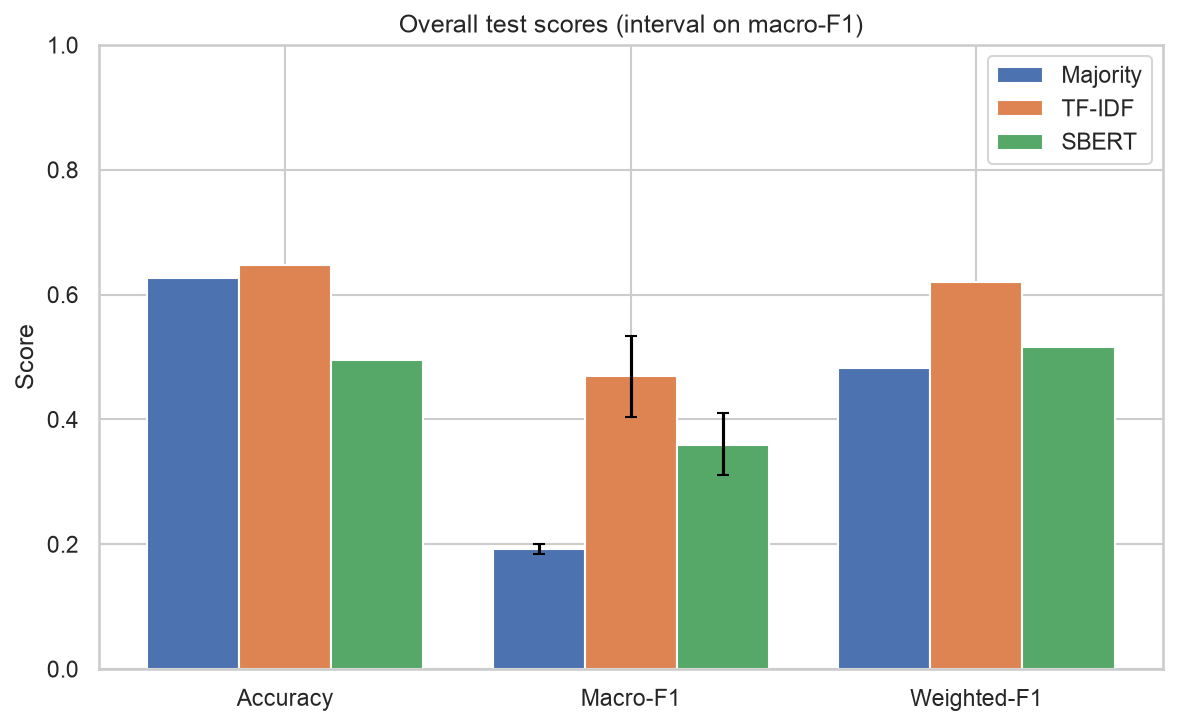

**comparison_per_class_f1.png**

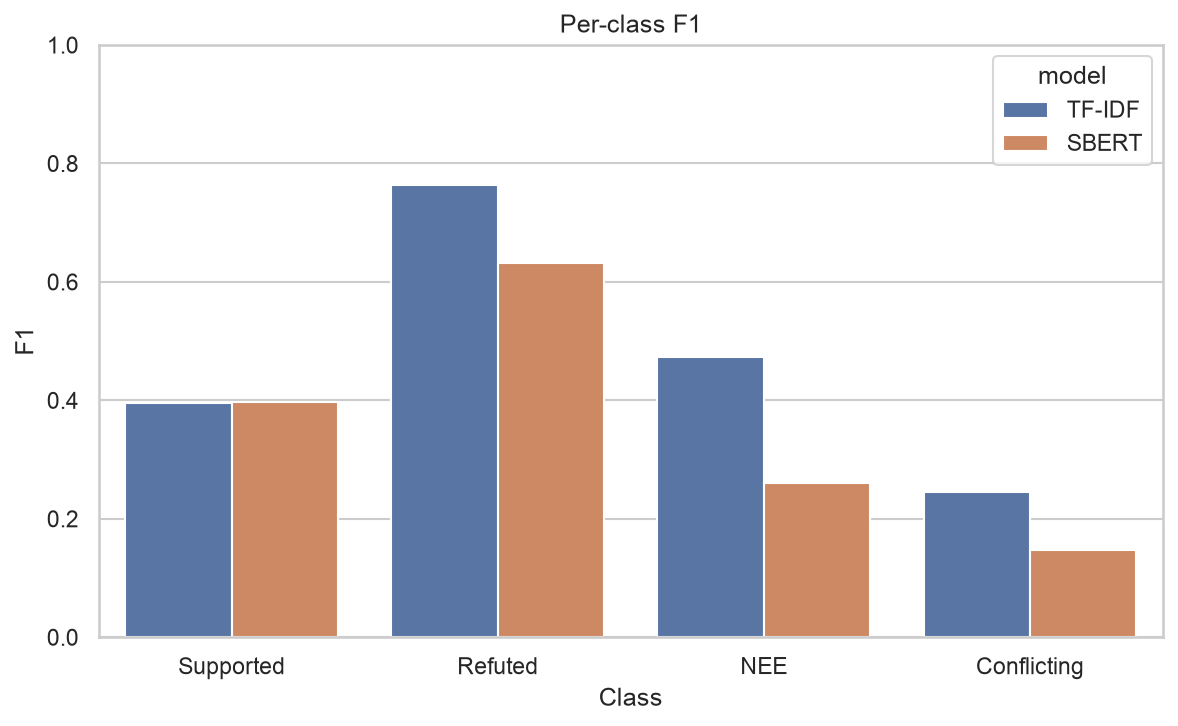

**ablation_input_modes.png**

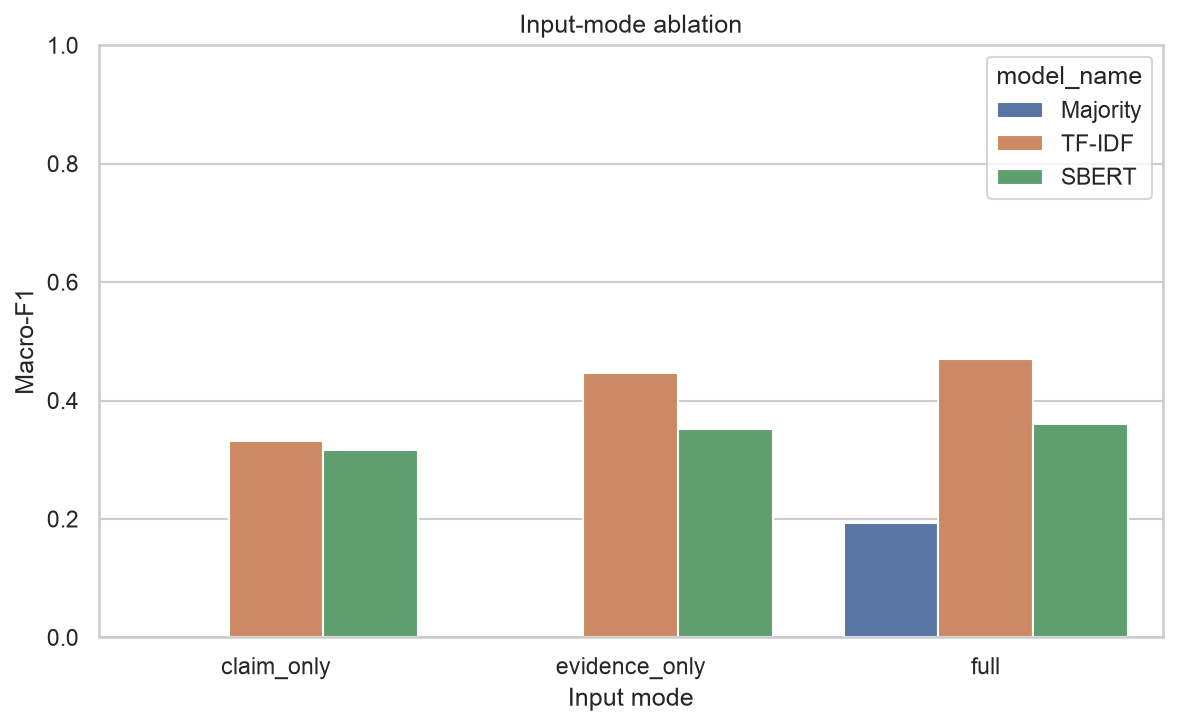

**cm_tfidf_lr_full.png**

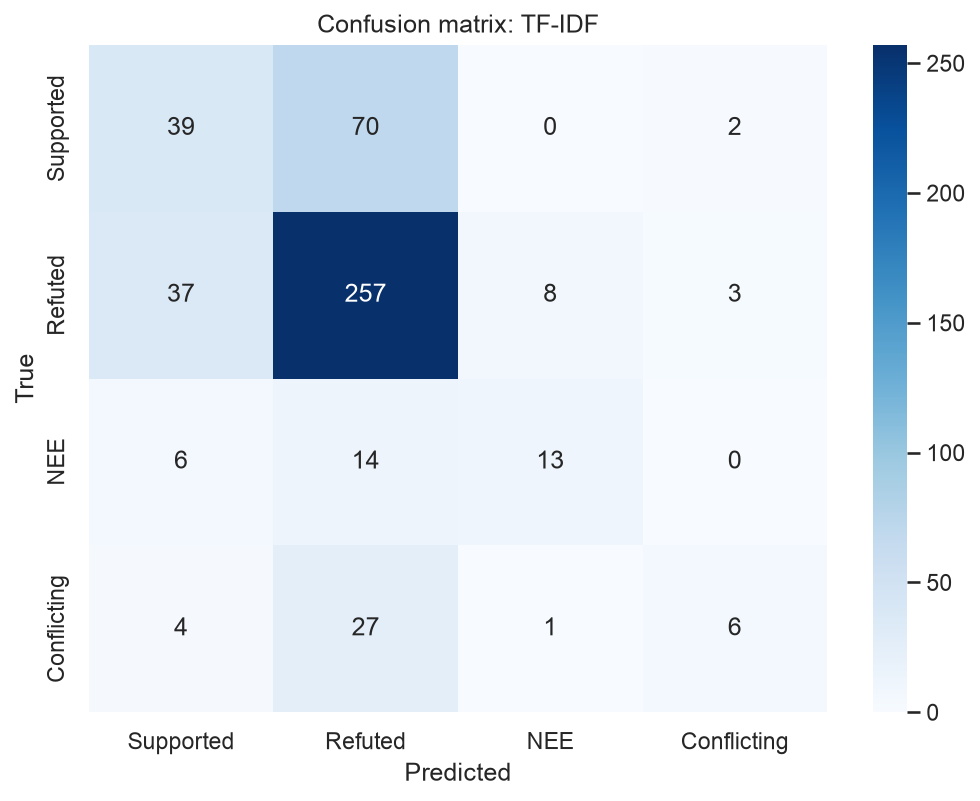

**cm_sbert_lr_full.png**

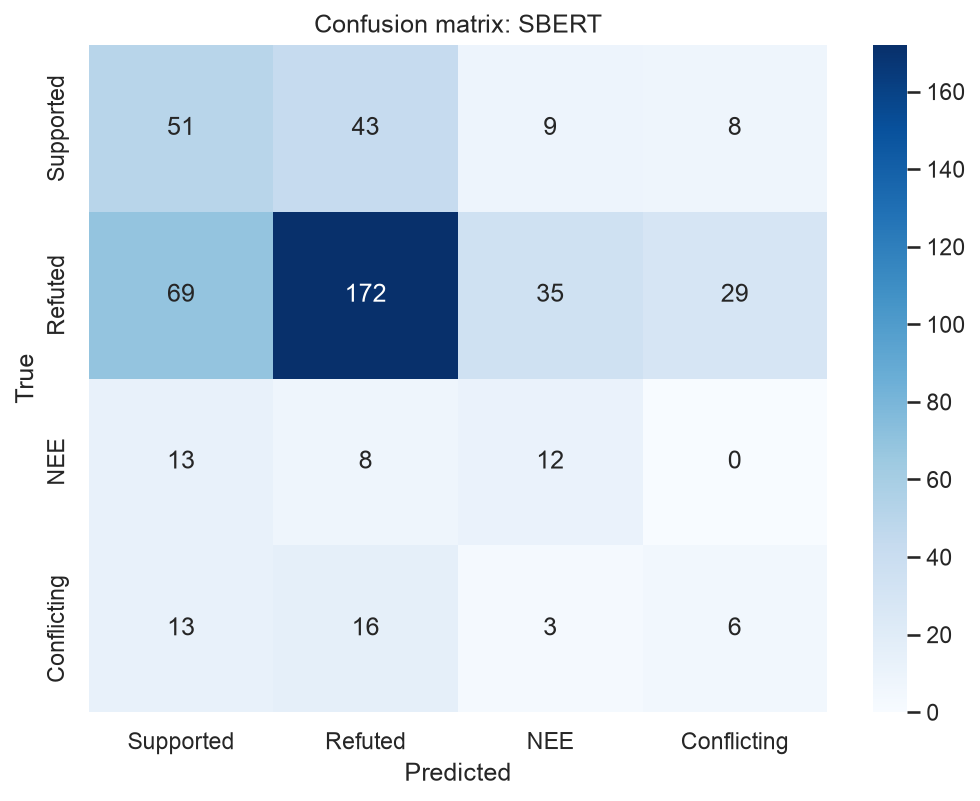

**cm_normalized_tfidf_lr_full.png**

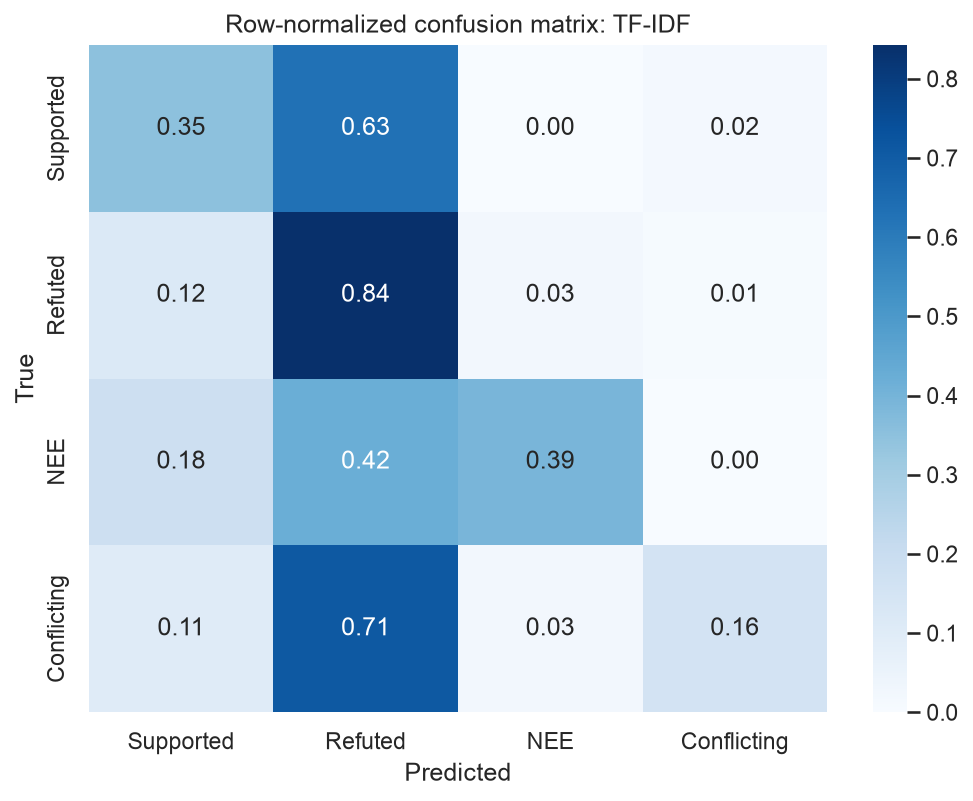

**cm_normalized_sbert_lr_full.png**

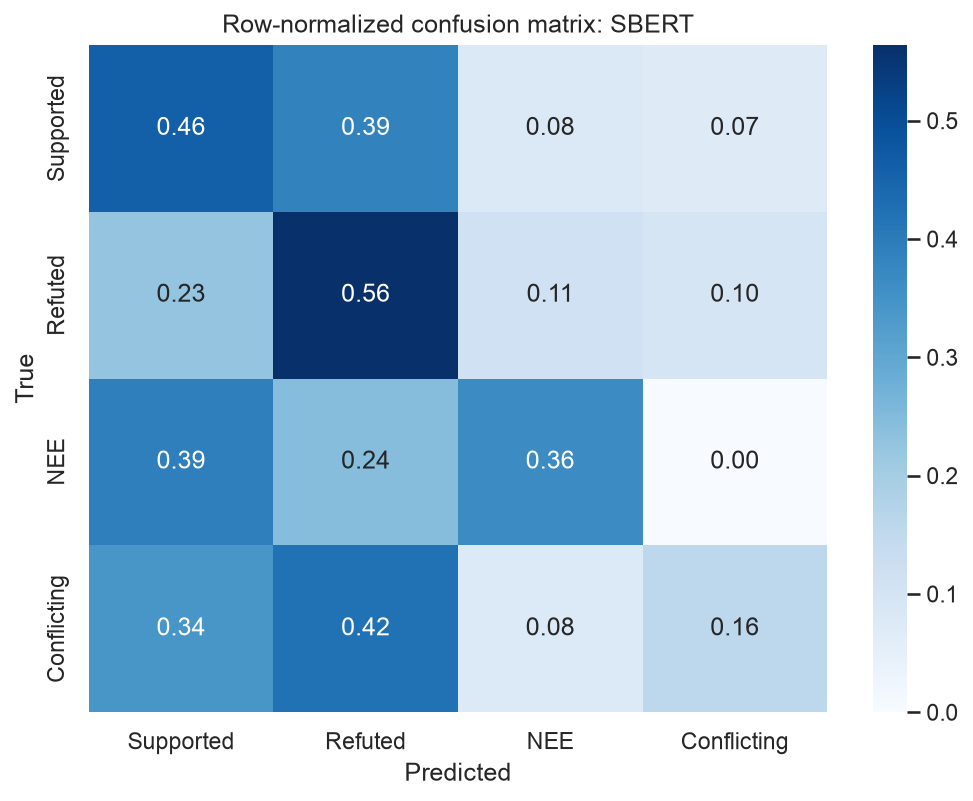

**per_class_prf_tfidf_lr.png**

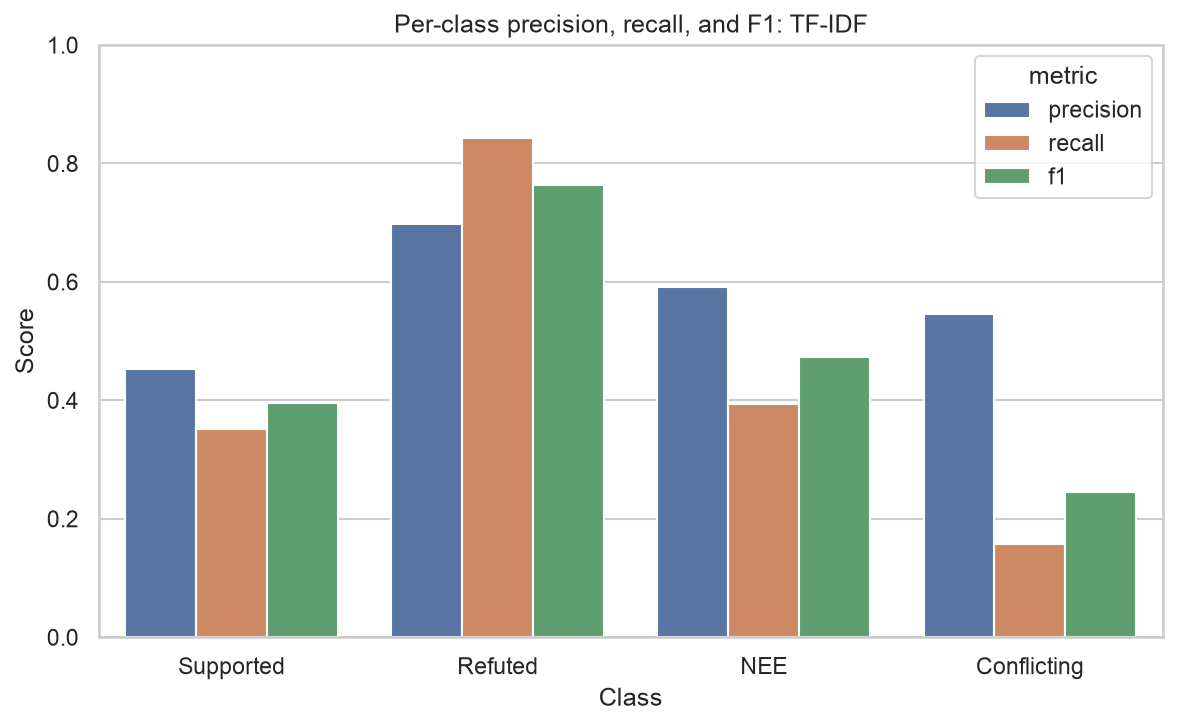

**per_class_prf_sbert_lr.png**

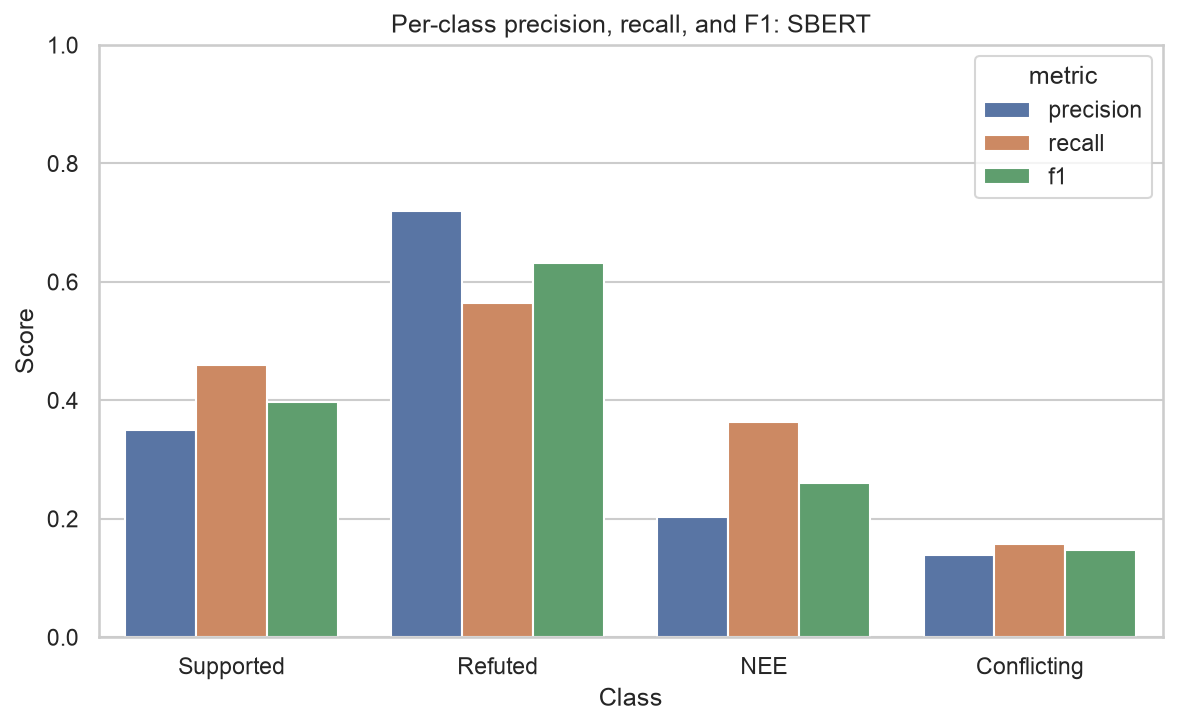

**error_reason_counts.png**

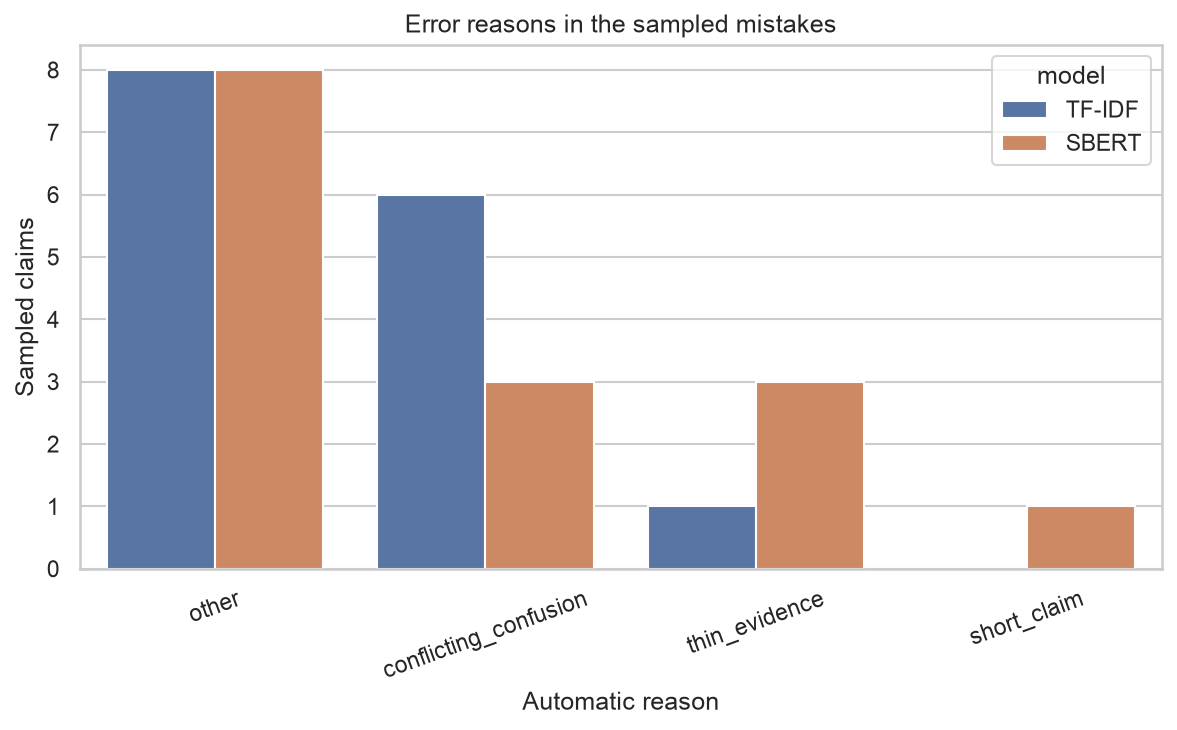

In [5]:
names = [
    "comparison_overall.png",
    "comparison_per_class_f1.png",
    "ablation_input_modes.png",
    "cm_tfidf_lr_full.png",
    "cm_sbert_lr_full.png",
    "cm_normalized_tfidf_lr_full.png",
    "cm_normalized_sbert_lr_full.png",
    "per_class_prf_tfidf_lr.png",
    "per_class_prf_sbert_lr.png",
    "error_reason_counts.png",
]
for name in names:
    path = C.FIGURES_DIR / name
    if not path.exists():
        raise FileNotFoundError(path)
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(path)))


## Error analysis

Automatic reasons for a stratified sample of mistakes. `manual_reason` is left blank.

In [6]:
summary = (C.ERRORS_DIR / "summary.md").read_text(encoding="utf-8")
display(Markdown(summary))
errors = pd.read_csv(C.ERRORS_DIR / "sbert_lr_errors.csv")
errors[["claim_id", "true", "pred_tfidf", "pred_sbert", "auto_reason"]].head(10)


# Error analysis

Reasons are assigned automatically by the first matching rule. `manual_reason` is left empty for the team to fill in.

## Counts

| model | reason | count |
| --- | --- | --- |
| tfidf_lr | other | 8 |
| tfidf_lr | conflicting_confusion | 6 |
| tfidf_lr | thin_evidence | 1 |
| sbert_lr | other | 8 |
| sbert_lr | conflicting_confusion | 3 |
| sbert_lr | thin_evidence | 3 |
| sbert_lr | short_claim | 1 |

## Examples

### tfidf_lr

- claim 34: true Supported; TF-IDF Refuted; SBERT Supported; reason other. The United States, New Zealand, U.K., Australia, and the EU have not included the NDF in their official list of terrorist groups.
- claim 50: true Conflicting Evidence/Cherrypicking; TF-IDF Refuted; SBERT Refuted; reason conflicting_confusion. Twitter now putting warnings on tweets that are just unedited clips of Biden saying he would end fracking
- claim 115: true Conflicting Evidence/Cherrypicking; TF-IDF Refuted; SBERT Refuted; reason conflicting_confusion. More people who wear masks become sick with COVID-19 compared to non-mask wearers
- claim 148: true Conflicting Evidence/Cherrypicking; TF-IDF Refuted; SBERT Supported; reason conflicting_confusion. U.S. President Donald Trump has suspended all travel from China.
- claim 170: true Supported; TF-IDF Refuted; SBERT Refuted; reason other. U.S. President Donald Trump has departed Walter Reed hospital just a few days after testing positive for COVID-19.

### sbert_lr

- claim 50: true Conflicting Evidence/Cherrypicking; TF-IDF Refuted; SBERT Refuted; reason conflicting_confusion. Twitter now putting warnings on tweets that are just unedited clips of Biden saying he would end fracking
- claim 53: true Supported; TF-IDF Refuted; SBERT Refuted; reason thin_evidence. The FBI is in possession of the president of the US's son Hunter Biden's laptop.
- claim 64: true Refuted; TF-IDF Refuted; SBERT Supported; reason other. Eric Trump, Donald J. Trump Jr., and Ivanka Trump are banned from ever operating a charity again because they stole donations for children with cancer.
- claim 70: true Refuted; TF-IDF Refuted; SBERT Not Enough Evidence; reason other. Dr Anthony Fauci wrote a paper regarding the Spanish Flu and stated that the majority of deaths in 1918-1919 was because of bacterial pneumonia from wearing masks.
- claim 115: true Conflicting Evidence/Cherrypicking; TF-IDF Refuted; SBERT Refuted; reason conflicting_confusion. More people who wear masks become sick with COVID-19 compared to non-mask wearers

## Disagreements

- claim 2 (sbert wins): true Refuted; TF-IDF Not Enough Evidence; SBERT Refuted. Due to Imran Khan's criticism of Macron's comments on Islam, French authorities cancelled the visas of 183 Pakistani citizens and deported 118 from the country.
- claim 32 (sbert wins): true Supported; TF-IDF Refuted; SBERT Supported. The New York post Endorsed Donald trumps bid for re-election.
- claim 93 (sbert wins): true Supported; TF-IDF Refuted; SBERT Supported. US Judge Amy Coney Barrett graduated at the top of her law school class at Notre Dame Law School
- claim 100 (sbert wins): true Conflicting Evidence/Cherrypicking; TF-IDF Refuted; SBERT Conflicting Evidence/Cherrypicking. US president Joe Biden (candidate at the time of claim) supports the new green deal (The Green New Deal is a nonbinding resolution, introduced by Rep. Alexandri...
- claim 181 (sbert wins): true Supported; TF-IDF Refuted; SBERT Supported. The ex-Prime Minister of India Lal Bahadur Shastri took a loan to buy a car.
- claim 297 (sbert wins): true Supported; TF-IDF Refuted; SBERT Supported. Sightway Capital is owned by Two Sigma Investments.
- claim 374 (sbert wins): true Refuted; TF-IDF Supported; SBERT Refuted. $400,000 ... is more money than I’ve ever made” in a year
- claim 412 (sbert wins): true Conflicting Evidence/Cherrypicking; TF-IDF Supported; SBERT Conflicting Evidence/Cherrypicking. Sen. Martha McSally “supported a plan to turn Medicare into a voucher program and ‘shift costs’ onto seniors” and “even supported raising the retirement age.
- claim 449 (sbert wins): true Supported; TF-IDF Refuted; SBERT Supported. All India Institute of Medical Sciences Nursing Officer Recruitment Common Eligibility Test 2020 was postponed.
- claim 482 (sbert wins): true Refuted; TF-IDF Conflicting Evidence/Cherrypicking; SBERT Refuted. This Democratic Party of Joe Biden is pushing the so-called Green New Deal. If given power, they would essentially ban animal agriculture and eliminate gas-powe...
- claim 64 (tfidf wins): true Refuted; TF-IDF Refuted; SBERT Supported. Eric Trump, Donald J. Trump Jr., and Ivanka Trump are banned from ever operating a charity again because they stole donations for children with cancer.
- claim 131 (tfidf wins): true Refuted; TF-IDF Refuted; SBERT Supported. We do not know where Covid-19 places among causes of death because the data is not published.
- claim 155 (tfidf wins): true Supported; TF-IDF Supported; SBERT Refuted. Trump said 'there were fine people on both sides' in far-right protests.
- claim 164 (tfidf wins): true Refuted; TF-IDF Refuted; SBERT Not Enough Evidence. OPCW scenario of the Navalny case is a fantastic story and a planned conspiracy scenario
- claim 193 (tfidf wins): true Refuted; TF-IDF Refuted; SBERT Supported. Two E-6B Mercury planes were deployed because of US President Trump's positive COVID-19 test.
- claim 206 (tfidf wins): true Not Enough Evidence; TF-IDF Not Enough Evidence; SBERT Supported. There was a 40% drop in oil prices in Nigeria.
- claim 246 (tfidf wins): true Supported; TF-IDF Supported; SBERT Conflicting Evidence/Cherrypicking. A Maryland man was sentenced to a year in jail for throwing parties.
- claim 260 (tfidf wins): true Refuted; TF-IDF Refuted; SBERT Conflicting Evidence/Cherrypicking. False Facebook posts claim Philippine vice president demanded multi-billion dollar budget for her office in 2021
- claim 420 (tfidf wins): true Refuted; TF-IDF Refuted; SBERT Supported. US President Trump issued an executive order for the White House to take over all electrical grids, which will include internet servers, broadcasting systems an...
- claim 460 (tfidf wins): true Refuted; TF-IDF Refuted; SBERT Supported. Donald Trump says Biden "is even talking about taking the wall down."


,claim_id,true,pred_tfidf,pred_sbert,auto_reason
0,50,Conflicting Evidence/Cherrypicking,Refuted,Refuted,conflicting_confusion
1,53,Supported,Refuted,Refuted,thin_evidence
2,64,Refuted,Refuted,Supported,other
3,70,Refuted,Refuted,Not Enough Evidence,other
4,115,Conflicting Evidence/Cherrypicking,Refuted,Refuted,conflicting_confusion
5,118,Refuted,Refuted,Supported,short_claim
6,215,Not Enough Evidence,Supported,Supported,other
7,259,Refuted,Refuted,Supported,thin_evidence
8,294,Supported,Refuted,Refuted,other
9,327,Refuted,Refuted,Supported,other
